# Project 2: Image Classification

## Notebook 2 — Cleaning, Preprocessing & Image EDA

# Note: 
Code source is from instructor GitHub and modified for the purpose of the project execution
--------------------------------------------------------------------------------------------------------------------------------------------------------
Data understanding and preparation. This notebook contains no model training, balancing, augmentation, or explanation maps.

**Recorded results:** I loaded 1,200 acquisition records, visually reviewed nine exact-duplicate groups, and removed 14 manually selected files. The saved post-removal scan retained **395 claw-hammer, 394 ball-peen-hammer, and 397 sledgehammer images (1,186 total)**. All three classes exceed the 200-image numerical minimum. The recorded export contains **948 training images and 238 test images**, stratified with `random_state=42`.

**Sequence:** Independent loading → inventory and human duplicate review → explicit filename removals → retention accounting → image EDA → RGB/resize and class means → stratified 80/20 split → external arrays and mapping.

### 0. Setup and independent Notebook 1 handoff

**Task:** Load the persisted configuration, source manifest, and external class folders without reusing Notebook 1 variables.

**Decision and explanation:** I locate the repository from its configuration and manifest, explicitly set `P2_DATA_ROOT` to my Windows `Images` folder, and validate labels, paths, boolean readability flags, and preprocessing settings. Raw files remain in `Images/raw/<label>` and exported arrays in `Images/prepared`, outside the repository. This makes the data location visible and keeps the handoff independent of a previous notebook kernel.

**Recorded outcome:** The setup loaded **1,200 manifest rows**. The printed paths below show the actual Windows locations used in the saved run.


In [24]:
from pathlib import Path
import os
import sys
import json
import random
import hashlib
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split

# Locate the repository independently of Notebook 1.
working_directory = Path.cwd().resolve()
repository_candidates = [
    working_directory,
    *working_directory.parents
]

REPO_ROOT = next(
    (
        directory
        for directory in repository_candidates
        if (directory / 'config/project.json').is_file()
        and (directory / 'data/P2_manifest.csv').is_file()
    ),
    None
)

if REPO_ROOT is None:
    raise FileNotFoundError(
        'Could not locate config/project.json and '
        'data/P2_manifest.csv. Open this notebook from '
        'the project repository.'
    )

sys.path.insert(0, str(REPO_ROOT / 'notebooks'))
sys.path.insert(0, str(REPO_ROOT / 'app'))

from pipeline_utils import (
    ROOT,
    load_config,
    save_json,
    digest,
    checked_manifest,
    as_bool,
    resize_rgb,
    pixel_hash,
    dhash
)

ROOT = Path(ROOT).resolve()
assert ROOT == REPO_ROOT, (
    'pipeline_utils points to a different repository.'
)

# Existing dataset location from Notebook 1.
os.environ['P2_DATA_ROOT'] = (
    r'C:\Users\lawra\Fall 2026-2027 Semester Document'
    r'\MSDS 565-01\Project 2 Image Classification\Images'
)

config, DATA_ROOT = load_config(require_confirmation=False)
DATA_ROOT = Path(DATA_ROOT).expanduser().resolve()

MANIFEST_PATH = ROOT / 'data/P2_manifest.csv'
CONTRACT_PATH = ROOT / 'data/P2_dataset_contract.json'

if CONTRACT_PATH.exists():
    contract = json.loads(
        CONTRACT_PATH.read_text(encoding='utf-8')
    )
    assert contract['class_queries'] == config['class_queries'], (
        'Class queries differ from the Notebook 1 handoff. '
        'Reconcile the configuration before continuing.'
    )
    assert contract['raw_subdirectory'] == 'raw', (
        'Unexpected raw-image subdirectory in the dataset contract.'
    )

RAW = DATA_ROOT / 'raw'
PREPARED = DATA_ROOT / 'prepared'
LABELS = list(config['class_queries'])

assert not DATA_ROOT.is_relative_to(ROOT), (
    'Images and prepared arrays must remain outside the repository.'
)
assert RAW.is_dir(), f'Missing dataset folder: {RAW}'
assert 3 <= len(LABELS) <= 10
assert config['seed'] == 42
assert config['resize_strategy'] == 'pad'
assert tuple(config['target_size']) == (224, 224)
assert len(config['padding_rgb']) == 3
assert all(0 <= value <= 255 for value in config['padding_rgb'])

for label in LABELS:
    assert (RAW / label).is_dir(), (
        f'Missing class folder: {RAW / label}'
    )

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
pd.set_option('display.max_rows', 25)


def read_manifest():
    """Read the persisted Notebook 1 handoff independently."""
    frame = checked_manifest(config).copy()

    required = {
        'filename', 'label', 'source_url',
        'query', 'readable'
    }
    assert required.issubset(frame.columns), (
        f'Missing manifest columns: {required - set(frame.columns)}'
    )
    assert not frame.empty
    assert not frame.duplicated(['label', 'filename']).any()
    assert set(frame['label']) == set(LABELS), (
        'Manifest labels do not match the configured classes.'
    )

    # Avoid treating the string "False" as the boolean True.
    readable_values = (
        frame['readable'].astype(str).str.strip().str.lower()
    )
    boolean_mapping = {
        'true': True,
        'false': False,
        '1': True,
        '0': False
    }
    assert readable_values.isin(boolean_mapping).all(), (
        'The readable column contains invalid boolean values.'
    )
    frame['readable'] = (
        readable_values.map(boolean_mapping).astype(bool)
    )

    # Each manifest entry must resolve inside its class folder.
    for row in frame.itertuples(index=False):
        class_directory = (RAW / row.label).resolve()
        image_path = (class_directory / row.filename).resolve()

        assert class_directory.parent == RAW.resolve()
        assert image_path.parent == class_directory, (
            f'Unsafe manifest filename: {row.filename}'
        )

    return frame


manifest = read_manifest()

print('Project 2: Image Classification')
print('Dataset root:', DATA_ROOT)
print('Scraped images:', RAW)
print('Prepared arrays:', PREPARED)
print('Manifest:', MANIFEST_PATH)
print('Loaded manifest independently:', len(manifest), 'rows')

Project 2: Image Classification
Dataset root: C:\Users\lawra\Fall 2026-2027 Semester Document\MSDS 565-01\Project 2 Image Classification\Images
Scraped images: C:\Users\lawra\Fall 2026-2027 Semester Document\MSDS 565-01\Project 2 Image Classification\Images\raw
Prepared arrays: C:\Users\lawra\Fall 2026-2027 Semester Document\MSDS 565-01\Project 2 Image Classification\Images\prepared
Manifest: C:\Users\lawra\Fall 2026-2027 Semester Document\MSDS 565-01\Project 2 Image Classification\Project_2_Image_Classification\Project-2-Image-Classification\data\P2_manifest.csv
Loaded manifest independently: 1200 rows


### 1.1 Inventory Images And Assist Manual Review

**Task:** Inspect Notebook 1's acquisition handoff and generate review aids.

**Decision:** I reload the manifest and inspect each `raw/<label>/<filename>` file. PIL decoding establishes file integrity; human inspection determines subject correctness and whether visually similar images should be removed.

**Steps taken:**

1. Check file presence and fully decode each image with `image.load()`.
2. Record width, height, aspect ratio, a file checksum, a decoded-pixel hash, and a 64-bit difference hash.
3. Compare images within and across all three classes. Flag a pair when the decoded-pixel hashes match or its difference-hash Hamming distance is at most four.
4. Save `P2_inventory.csv` and `P2_duplicate_candidates.csv` outside the repository, then inspect duplicate groups visually.

In [9]:
def scan_manifest(frame):
    """Inspect files without deleting or changing them."""
    records = []

    for row in frame.itertuples(index=False):
        path = RAW / row.label / row.filename

        entry = {
            'filename': row.filename,
            'label': row.label,
            'exists': path.is_file(),
            'width': np.nan,
            'height': np.nan,
            'aspect_ratio': np.nan,
            'pixel_sha256': '',
            'dhash64': '',
            'file_sha256': '',
            'decodable': False,
            'error': ''
        }

        try:
            with Image.open(path) as image:
                image.load()

                entry.update({
                    'width': image.width,
                    'height': image.height,
                    'aspect_ratio': image.width / image.height,
                    'pixel_sha256': pixel_hash(image),
                    'dhash64': f'{dhash(image):016x}',
                    'decodable': True
                })

            entry['file_sha256'] = digest(path)

        except (OSError, ValueError) as error:
            entry['error'] = str(error)

        records.append(entry)

    return pd.DataFrame(records)


def find_duplicate_candidates(table):
    """Suggest pairs for human review within and across classes."""
    valid_rows = list(
        table.loc[table['decodable']].itertuples(index=False)
    )
    pairs = []

    for index, left in enumerate(valid_rows):
        for right in valid_rows[index + 1:]:
            distance = (
                int(left.dhash64, 16)
                ^ int(right.dhash64, 16)
            ).bit_count()

            exact = left.pixel_sha256 == right.pixel_sha256

            if exact or distance <= 4:
                pairs.append({
                    'left_label': left.label,
                    'left_filename': left.filename,
                    'right_label': right.label,
                    'right_filename': right.filename,
                    'exact': exact,
                    'dhash_distance': distance
                })

    return pd.DataFrame(
        pairs,
        columns=[
            'left_label', 'left_filename',
            'right_label', 'right_filename',
            'exact', 'dhash_distance'
        ]
    )


manifest = read_manifest()
inventory = scan_manifest(manifest)
candidates = find_duplicate_candidates(inventory)

inventory.to_csv(
    DATA_ROOT / 'P2_inventory.csv', index=False
)
candidates.to_csv(
    DATA_ROOT / 'P2_duplicate_candidates.csv', index=False
)

inventory_summary = (
    inventory.groupby('label')
    .agg(
        manifest_records=('filename', 'size'),
        files_present=('exists', 'sum'),
        decodable=('decodable', 'sum')
    )
    .reindex(LABELS)
)

inventory_summary['missing'] = (
    inventory_summary['manifest_records']
    - inventory_summary['files_present']
)
inventory_summary['present_but_unreadable'] = (
    inventory_summary['files_present']
    - inventory_summary['decodable']
)

display(inventory_summary)
display(candidates.head(10))

print('Review class folders:', RAW)
print('Duplicate candidate pairs:', len(candidates))
print(
    'Candidate pairs are suggestions, not confirmed duplicates. '
    'Review subjects and duplicates manually.'
)

,manifest_records,files_present,decodable,missing,present_but_unreadable
label,,,,,
claw-hammer,400,400,400,0,0
ball-peen-hammer,400,400,400,0,0
sledgehammer,400,400,400,0,0


,left_label,left_filename,right_label,right_filename,exact,dhash_distance
0,claw-hammer,b5a9a596f05e_claw-hammer_0000.jpg,ball-peen-hammer,27e532453bcf_ball-peen-hammer_0084.jpg,False,2
1,claw-hammer,b5a9a596f05e_claw-hammer_0000.jpg,ball-peen-hammer,27e532453bcf_ball-peen-hammer_0250.jpg,False,4
2,claw-hammer,b5a9a596f05e_claw-hammer_0000.jpg,sledgehammer,d2b2120c14bc_sledgehammer_0003.jpg,False,2
3,claw-hammer,b5a9a596f05e_claw-hammer_0000.jpg,sledgehammer,d2b2120c14bc_sledgehammer_0018.jpg,False,3
4,claw-hammer,b5a9a596f05e_claw-hammer_0000.jpg,sledgehammer,d2b2120c14bc_sledgehammer_0048.jpg,False,3
5,claw-hammer,b5a9a596f05e_claw-hammer_0000.jpg,sledgehammer,d2b2120c14bc_sledgehammer_0140.jpg,False,3
6,claw-hammer,b5a9a596f05e_claw-hammer_0000.jpg,sledgehammer,d2b2120c14bc_sledgehammer_0169.jpg,False,1
7,claw-hammer,b5a9a596f05e_claw-hammer_0000.jpg,sledgehammer,d2b2120c14bc_sledgehammer_0380.jpg,False,0
8,claw-hammer,b5a9a596f05e_claw-hammer_0001.jpg,claw-hammer,b5a9a596f05e_claw-hammer_0024.jpg,False,2
9,claw-hammer,b5a9a596f05e_claw-hammer_0001.jpg,claw-hammer,b5a9a596f05e_claw-hammer_0092.jpg,False,2


Review class folders: C:\Users\lawra\Fall 2026-2027 Semester Document\MSDS 565-01\Project 2 Image Classification\Images\raw
Duplicate candidate pairs: 4541
Candidate pairs are suggestions, not confirmed duplicates. Review subjects and duplicates manually.


#### Outcome and Interpretation — Initial Inventory

The saved **pre-removal** inventory contains **400 present and decodable files per class**, or **1,200 total**, with **zero missing files and zero present-but-unreadable files**.

The similarity screen returned **4,541 candidate pairs**. This is a count of pairs, not 4,541 images or confirmed duplicates: one image can occur in many pairs, and different hammer photographs can have similar hashes. The separate exact-hash grouping below identified **nine groups involving 20 files**.

This initial output remains as acquisition evidence. It was not rerun after the removals in this saved copy; Section 1.2 independently rescanned the folders and established the later retained counts. The saved candidate count does not demonstrate that all near-duplicate candidates were visually reviewed.


#### Exact-Duplicate Review Aid

**Decision and explanation:** I separated exact pixel matches from the broader similarity-pair list and displayed their class labels, filenames, and images before selecting removals. The saved report below contains nine groups involving 20 files, including three groups with conflicting class labels. A similarity score alone did not determine which image or label to retain.

**Recorded outcome:** The saved cell shows all nine groups in its table and renders group 1. The additional screenshots below preserve the visual review of all nine groups shared during the cleaning workflow. These are pre-removal review records, not a claim that duplicates still remain after the later scan.


9 duplicate groups found.


,duplicate_group,label,filename
810,1,sledgehammer,d2b2120c14bc_sledgehammer_0010.jpg
1148,1,sledgehammer,d2b2120c14bc_sledgehammer_0348.jpg
243,2,claw-hammer,b5a9a596f05e_claw-hammer_0243.jpg
307,2,claw-hammer,b5a9a596f05e_claw-hammer_0307.jpg
1016,3,sledgehammer,d2b2120c14bc_sledgehammer_0216.jpg
1146,3,sledgehammer,d2b2120c14bc_sledgehammer_0346.jpg
750,4,ball-peen-hammer,27e532453bcf_ball-peen-hammer_0350.jpg
241,4,claw-hammer,b5a9a596f05e_claw-hammer_0241.jpg
744,5,ball-peen-hammer,27e532453bcf_ball-peen-hammer_0344.jpg
142,5,claw-hammer,b5a9a596f05e_claw-hammer_0142.jpg


,duplicate_group,label,filename,full_path
810,1,sledgehammer,d2b2120c14bc_sledgehammer_0010.jpg,C:\Users\lawra\Fall 2026-2027 Semester Documen...
1148,1,sledgehammer,d2b2120c14bc_sledgehammer_0348.jpg,C:\Users\lawra\Fall 2026-2027 Semester Documen...


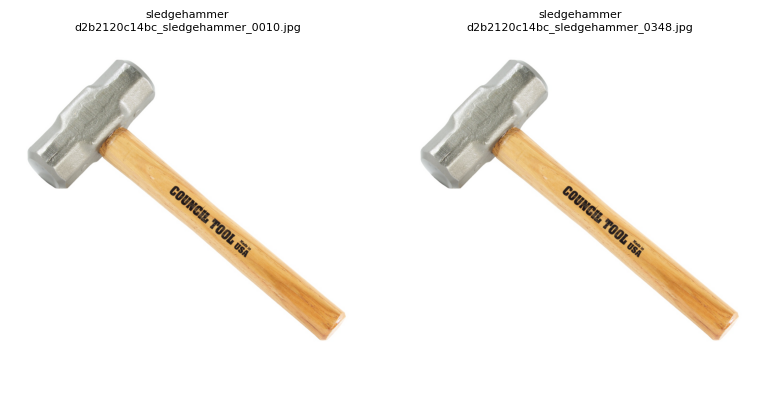

In [10]:
# Refresh the inventory and select readable duplicate records.
review_manifest = read_manifest()
review_inventory = scan_manifest(review_manifest)

review = review_inventory.merge(
    review_manifest[['label', 'filename', 'readable']],
    on=['label', 'filename'],
    validate='one_to_one'
)

review = review.loc[
    review['readable']
    & review['exists']
    & review['decodable']
].copy()

duplicates = review.loc[
    review['pixel_sha256'].duplicated(keep=False)
].copy()

if duplicates.empty:
    print('No exact duplicate groups remain.')
else:
    duplicates['duplicate_group'] = (
        duplicates.groupby('pixel_sha256', sort=True).ngroup() + 1
    )

    duplicates = duplicates.sort_values(
        ['duplicate_group', 'label', 'filename']
    )

    duplicates['full_path'] = [
        str(RAW / row.label / row.filename)
        for row in duplicates.itertuples(index=False)
    ]

    duplicates.to_csv(
        DATA_ROOT / 'P2_exact_duplicate_review.csv',
        index=False
    )

    group_count = duplicates['duplicate_group'].nunique()
    print(f'{group_count} duplicate groups found.')
    display(duplicates[[
        'duplicate_group', 'label', 'filename'
    ]])

    # Change GROUP_NUMBER to inspect each group.
    GROUP_NUMBER = 1

    # For groups containing more than eight files,
    # change START_IMAGE to 8, 16, etc.
    START_IMAGE = 0

    group = duplicates.loc[
        duplicates['duplicate_group'].eq(GROUP_NUMBER)
    ]
    examples = group.iloc[START_IMAGE:START_IMAGE + 8]

    if examples.empty:
        print('No images at this group number and starting position.')
    else:
        display(group[[
            'duplicate_group', 'label', 'filename', 'full_path'
        ]])

        fig, axes = plt.subplots(
            1, len(examples),
            figsize=(4 * len(examples), 4),
            squeeze=False
        )

        for axis, row in zip(
            axes[0], examples.itertuples(index=False)
        ):
            with Image.open(
                RAW / row.label / row.filename
            ) as image:
                axis.imshow(image.convert('RGB'))

            axis.set_title(
                f'{row.label}\n{row.filename}',
                fontsize=8
            )
            axis.axis('off')

        plt.tight_layout()
        plt.show()

#### Visual evidence used for the cleaning decisions

**Groups 1–3: duplicate tool photographs**

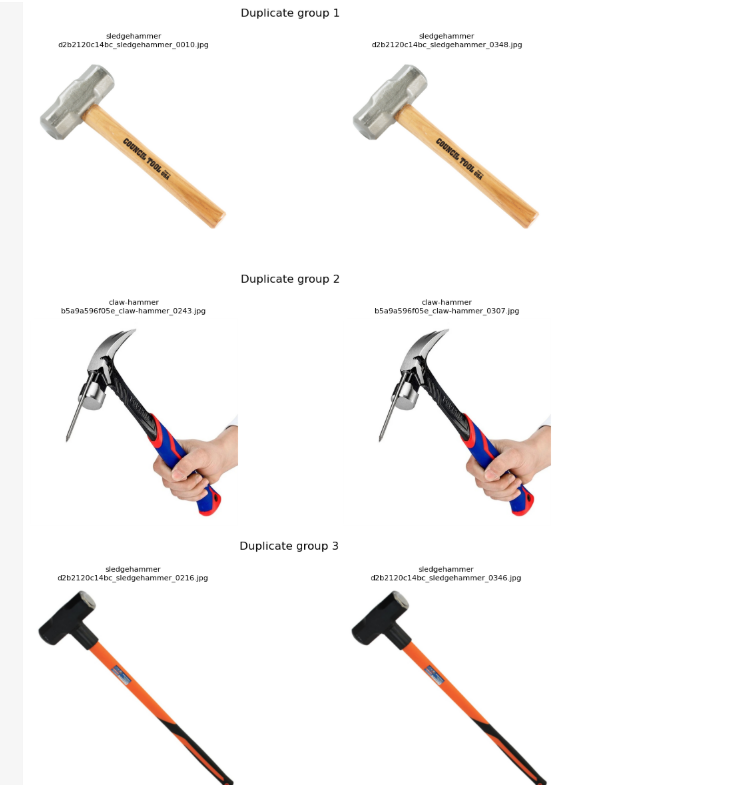

**Groups 4–5: cross-class comparison collages**

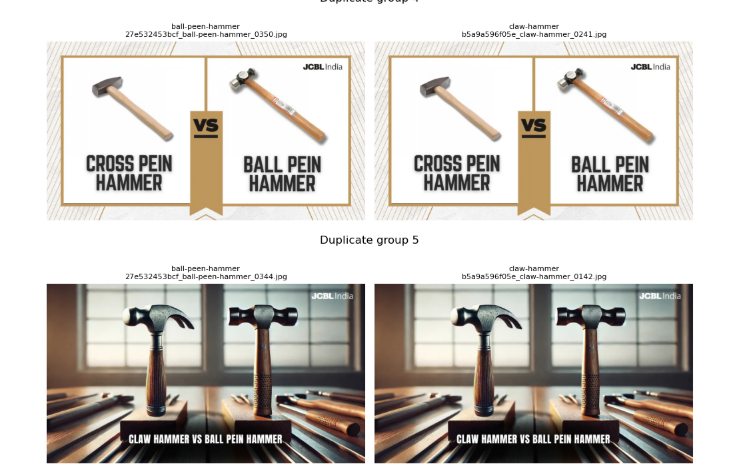

**Groups 6–8: repeated photographs and a multi-type diagram**

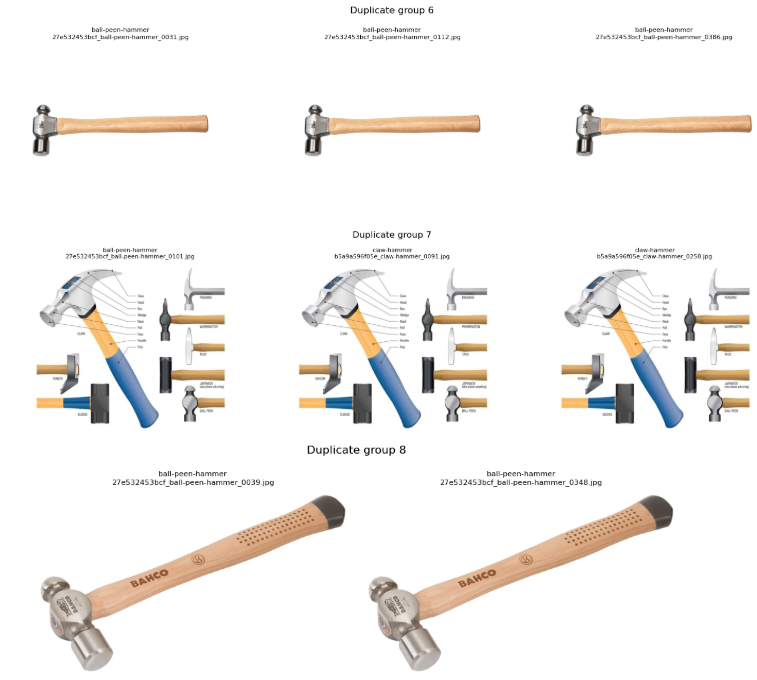

**Group 9: duplicate sledgehammer photograph**

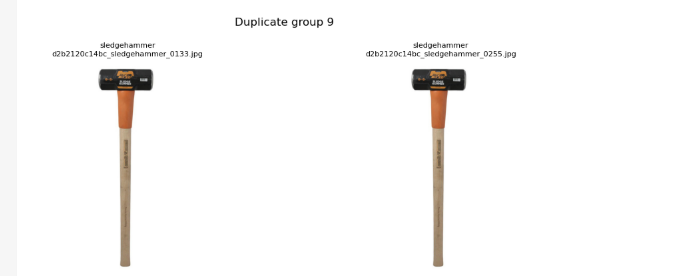

These screenshots record the original review state. The group table and accounting in Section 1.2 explain the subsequent decisions.


#### Apply the Manually Selected Filenames

**Task and decision:** Apply the 14 removals selected from visual review, using an explicit class-and-filename list. This is a helper for human decisions, not automated semantic cleaning.

**Explanation:** The code below touches only listed files, reports already-absent files on a repeat run, and leaves every acquisition record in the manifest. It does not classify images or delete all perceptual-hash candidates. The uploaded notebook has no saved output for this particular cell; the later independent scan verifies the post-removal counts. Run the retained cell on the Windows dataset only when applying these documented choices, not to reset or repeat the original acquisition.


### 1.2 Manual Cleaning Summary and Retained Counts

**Task:** Document the actual human cleaning decisions and reconcile the resulting files with all acquisition records.

**Decision:** I used visual review to select removals. The computer grouped similar files and applied my explicit filename list; it did not decide whether a pictured subject was a valid hammer class.

**Steps taken:**

1. Display the nine exact-duplicate groups with class labels and filenames and compare their contents visually.
2. For groups 1, 2, 3, 6, 8, and 9, retain one suitable photograph per group and select seven extra copies for removal.
3. Remove all seven files in groups 4, 5, and 7 because they are comparison collages or diagrams containing multiple hammer types, rather than a single unambiguous class example.
4. Use the filename-specific Python deletion cell to apply these 14 manually chosen removals. I did not use an automatic rule that keeps the first image in every group or infers a correct class from a hash.
5. Reload the manifest, rescan the remaining files, and repeat the exact-hash check. Add/update `kept` while preserving all original rows, their order, and acquisition columns.

| Original review group | Visual finding | Action | Files removed |
|---|---|---|---:|
| 1 | Two copies of one sledgehammer photograph | Keep `_0010`; remove `_0348` | 1 |
| 2 | Two copies of one claw-hammer photograph | Keep `_0243`; remove `_0307` | 1 |
| 3 | Two copies of one sledgehammer photograph | Keep `_0216`; remove `_0346` | 1 |
| 4 | Cross-peen versus ball-peen comparison collage in two classes | Remove both class copies | 2 |
| 5 | Claw versus ball-peen comparison collage in two classes | Remove both class copies | 2 |
| 6 | Three copies of one ball-peen photograph | Keep `_0031`; remove `_0112` and `_0386` | 2 |
| 7 | Diagram showing several hammer types, present in two classes | Remove all three copies | 3 |
| 8 | Two copies of one ball-peen photograph | Keep `_0039`; remove `_0348` | 1 |
| 9 | Two copies of one sledgehammer photograph | Keep `_0133`; remove `_0255` | 1 |
| **Total** | **Seven extra photographic copies and seven unsuitable collage/diagram files** | **14 selected removals** | **14** |

The filename endings refer to the complete, class-specific filenames in the deletion cell and review reports. Group numbers describe the original nine-group report; a fresh scan can renumber the remaining groups.

**Explanation:** All 14 absent acquisition files are accounted for by the selected removal list and the observed class-count changes. Readability is retained as acquisition history; `kept` records survival after cleaning. This avoids deleting source records when image files are removed. The explicit deletion cell has no saved execution output in the uploaded notebook; the subsequent successful scan provides the saved evidence of the resulting file availability.

**Review limitation:** The source cell has both review flags set to `True`, but those flags are user confirmations, not an independent audit. The saved narrative and retained sample do not establish exhaustive subject or near-duplicate review. This section documents the completed nine-group review and 14 removals without claiming the rest of the corpus has been fully validated.


In [19]:
import shutil

# Change these only after completing the actual manual review.
MANUAL_CLEANING_COMPLETE = True
DUPLICATE_CANDIDATES_REVIEWED = True

CLEANING_SUMMARY = (
    'I visually reviewed nine exact-duplicate groups involving 20 files and '
    'manually selected 14 files for removal. An explicit filename list was '
    'used to apply those decisions: seven extra copies of tool photographs '
    'and seven comparison-collage or diagram files showing multiple hammer '
    'types were removed. The removals comprised five claw-hammer, six ball- '
    'peen-hammer, and three sledgehammer files. The saved post-removal scan '
    'passed the exact-duplicate check and retained 395 claw-hammer, 394 '
    'ball-peen-hammer, and 397 sledgehammer images, totaling 1186. The '
    'manifest preserved all 1200 acquisition rows and recorded kept '
    'decisions. Full subject and near-duplicate review is not established '
    'by the saved outputs; the retained sample still includes a product '
    'collage and an apparent parts-only listing requiring follow-up.'
)

# Refresh the manifest and inventory after any manual deletions.
manifest = read_manifest()
inventory = scan_manifest(manifest)
candidates = find_duplicate_candidates(inventory)

print('Dataset being checked:', RAW)

# Reject files that have no acquisition record.
known_ids = set(
    zip(manifest['label'], manifest['filename'])
)

unknown_files = [
    str(path)
    for label in LABELS
    for path in (RAW / label).iterdir()
    if path.is_file()
    and (label, path.name) not in known_ids
]

assert not unknown_files, (
    f'Unmanifested class files found: {unknown_files[:5]}. '
    'Resolve their provenance before continuing.'
)

# Report unreadable files that are still present.
unreadable_present = inventory.loc[
    inventory['exists'] & ~inventory['decodable']
]

if not unreadable_present.empty:
    display(unreadable_present[
        ['label', 'filename', 'error']
    ])

    raise RuntimeError(
        'Unreadable files remain in the class folders. '
        'Remove or resolve the listed files, then rerun this cell.'
    )

readable_lookup = manifest.set_index(
    ['label', 'filename']
)['readable']

inventory['readable_N1'] = [
    bool(readable_lookup.loc[(row.label, row.filename)])
    for row in inventory.itertuples(index=False)
]

# Present readable files must agree with Notebook 1's integrity record.
assert not (
    inventory['decodable'] & ~inventory['readable_N1']
).any(), (
    'Some present readable files were marked unreadable in Notebook 1. '
    'Reconcile the Notebook 1 integrity record before continuing.'
)

# These are provisional survivors until manual review is confirmed.
inventory['keep'] = (
    inventory['readable_N1']
    & inventory['exists']
    & inventory['decodable']
)

kept = (
    inventory.loc[inventory['keep']]
    .copy()
    .reset_index(drop=True)
)

# Show remaining exact duplicate groups and their actual locations.
duplicate_rows = kept.loc[
    kept['pixel_sha256'].duplicated(keep=False)
].copy()

if not duplicate_rows.empty:
    duplicate_rows['duplicate_group'] = (
        duplicate_rows.groupby(
            'pixel_sha256', sort=True
        ).ngroup() + 1
    )

    duplicate_rows['full_path'] = [
        str(RAW / row.label / row.filename)
        for row in duplicate_rows.itertuples(index=False)
    ]

    duplicate_rows = duplicate_rows.sort_values(
        ['duplicate_group', 'label', 'filename']
    )

    print(
        'Remaining exact duplicate groups:',
        duplicate_rows['duplicate_group'].nunique()
    )

    with pd.option_context(
        'display.max_colwidth', None,
        'display.max_rows', 100
    ):
        display(duplicate_rows[[
            'duplicate_group',
            'label',
            'filename',
            'full_path'
        ]])

    duplicate_report_path = (
        DATA_ROOT / 'P2_remaining_exact_duplicates.csv'
    )

    duplicate_rows.to_csv(
        duplicate_report_path,
        index=False
    )

    print('Duplicate report:', duplicate_report_path)

    raise RuntimeError(
        'Duplicate files are still present. Inspect each group using '
        'the duplicate-preview cell and manually remove extra or '
        'incorrectly labeled copies from the displayed locations. '
        'Then rerun this cell. No cleaning results were saved.'
    )

print('Exact-duplicate check passed.')

# Calculate provisional counts before checking manual confirmation.
support = (
    kept.groupby('label')
    .size()
    .reindex(LABELS, fill_value=0)
)
support.name = 'retained'

summary = (
    manifest.groupby('label')
    .agg(
        acquired=('filename', 'size'),
        readable_N1=('readable', 'sum')
    )
    .reindex(LABELS)
)

summary['retained'] = support
summary['removed_during_manual_cleaning'] = (
    summary['readable_N1'] - summary['retained']
)
summary['unreadable_N1'] = (
    summary['acquired'] - summary['readable_N1']
)
summary['clears_200'] = summary['retained'].ge(200)

assert summary['removed_during_manual_cleaning'].ge(0).all()

print(
    'Provisional counts: missing files count as manual removals '
    'only after you confirm that they were intentionally removed.'
)
display(summary)

# Passing an exact-hash check does not establish semantic correctness
# or completion of near-duplicate review.
assert MANUAL_CLEANING_COMPLETE, (
    'Review every class folder for incorrect subjects and unsuitable '
    'images. Then set MANUAL_CLEANING_COMPLETE = True.'
)

assert DUPLICATE_CANDIDATES_REVIEWED, (
    'Review duplicate candidates within and across classes, including '
    'near-duplicates. Then set DUPLICATE_CANDIDATES_REVIEWED = True.'
)

assert (
    CLEANING_SUMMARY.strip()
    and not CLEANING_SUMMARY.strip().startswith('REPLACE')
    and CLEANING_SUMMARY.strip() != (
        'Manual cleaning has not yet been completed. '
        'Notebook 1 confirmed file readability, but subject correctness '
        'and duplicate removal have not yet been verified.'
    )
), (
    'Replace CLEANING_SUMMARY with what you actually reviewed '
    'and removed.'
)

if not support.ge(200).all():
    raise RuntimeError(
        'At least one class has fewer than 200 retained images. '
        'Collect more genuine images in Notebook 1, review them, '
        f'and rerun Notebook 2. Counts: {support.to_dict()}. '
        'No cleaning results were saved.'
    )

# Preserve every acquisition row and column.
acquisition_before = manifest.drop(
    columns=['kept'], errors='ignore'
).copy(deep=True)

original_ids = list(
    zip(manifest['label'], manifest['filename'])
)

keep_lookup = inventory.set_index(
    ['label', 'filename']
)['keep']

manifest['kept'] = [
    bool(keep_lookup.loc[key])
    for key in original_ids
]

pd.testing.assert_frame_equal(
    acquisition_before,
    manifest.drop(columns=['kept'])
)

assert list(
    zip(manifest['label'], manifest['filename'])
) == original_ids

# Preserve the existing manifest before its first Notebook 2 update.
backup_path = ROOT / 'data/P2_manifest_before_N2.csv'

if not backup_path.exists():
    shutil.copy2(MANIFEST_PATH, backup_path)

# Write the complete updated manifest before replacing the existing CSV.
temporary_path = MANIFEST_PATH.with_suffix('.csv.tmp')
manifest.to_csv(temporary_path, index=False)
temporary_path.replace(MANIFEST_PATH)

summary.to_csv(ROOT / 'data/P2_cleaning_summary.csv')
inventory.to_csv(DATA_ROOT / 'P2_inventory.csv', index=False)
candidates.to_csv(
    DATA_ROOT / 'P2_duplicate_candidates.csv',
    index=False
)

save_json(ROOT / 'data/P2_manual_cleaning_summary.json', {
    'summary': CLEANING_SUMMARY,
    'manual_cleaning_complete': MANUAL_CLEANING_COMPLETE,
    'all_candidates_reviewed': DUPLICATE_CANDIDATES_REVIEWED,
    'remaining_candidate_pairs': len(candidates),
    'retained_per_class': {
        label: int(count)
        for label, count in support.items()
    }
})

display(Markdown(
    '**Manual cleaning summary:** ' + CLEANING_SUMMARY
))

for label, row in summary.iterrows():
    display(Markdown(
        f"**{label}:** "
        f"{int(row['removed_during_manual_cleaning'])} removed; "
        f"{int(row['retained'])} retained. "
        'The 200-image minimum is met.'
    ))

print('Cleaning results saved. Continue to Section 2.1.')

Dataset being checked: C:\Users\lawra\Fall 2026-2027 Semester Document\MSDS 565-01\Project 2 Image Classification\Images\raw
Exact-duplicate check passed.
Provisional counts: missing files count as manual removals only after you confirm that they were intentionally removed.


,acquired,readable_N1,retained,removed_during_manual_cleaning,unreadable_N1,clears_200
label,,,,,,
claw-hammer,400,400,395,5,0,True
ball-peen-hammer,400,400,394,6,0,True
sledgehammer,400,400,397,3,0,True


**Manual cleaning summary:** I visually reviewed nine exact-duplicate groups. I removed seven extra copies of tool photographs and seven comparison-collage or diagram files showing multiple hammer types. These removals comprised five claw-hammer images, six ball-peen-hammer images, and three sledgehammer images. The remaining dataset still requires full subject and near-duplicate review.

**claw-hammer:** 5 removed; 395 retained. The 200-image minimum is met.

**ball-peen-hammer:** 6 removed; 394 retained. The 200-image minimum is met.

**sledgehammer:** 3 removed; 397 retained. The 200-image minimum is met.

Cleaning results saved. Continue to Section 2.1.


#### Outcome — Verified Post-Removal Accounting

The saved rerun reports **“Exact-duplicate check passed.”** Its counts reconcile as follows:

| Class | Acquired | Readable at acquisition | Removed | Retained | Above 200 |
|---|---:|---:|---:|---:|---|
| Claw hammer | 400 | 400 | 5 | 395 | Yes |
| Ball-peen hammer | 400 | 400 | 6 | 394 | Yes |
| Sledgehammer | 400 | 400 | 3 | 397 | Yes |
| **Total** | **1,200** | **1,200** | **14** | **1,186** | **All classes** |

The removal rate is **14 / 1,200 = 1.17%**; **98.83%** of acquisition records remain represented by retained files. The manifest keeps all **1,200 acquisition rows**, with **1,186 retained** and **14 removed** decisions in `kept`, as implied by the successful source code and retention table. The saved cell reports that the cleaning results were written.

**Interpretation:** The 200-image numerical floor is met for every class, and the post-removal scan found no repeated decoded-pixel hashes among retained files. This does not prove that all remaining subjects are correct or that near-duplicates are absent. The original saved summary display above uses earlier wording; the table and successful check are the follow-up verification, and the revised `CLEANING_SUMMARY` source incorporates them. Complete subject and near-duplicate review remains unresolved, as illustrated in Section 2.1.


### 2.1 Inspect at Least Eight Retained Images Per Class

**Task:** Show the reader what the retained working dataset actually contains.

**Decision:** Sample **eight images per class** reproducibly with seed 42, instead of showing only the earliest search hits.

**Steps taken:** Sample from the 395 claw-hammer, 394 ball-peen-hammer, and 397 sledgehammer records; display a 3-by-8 labeled grid using the shared RGB and padding helper. The grid is embedded in notebook output.

**Explanation:** Twenty-four examples expose differences in framing, backgrounds, tool orientation, visible head geometry, branding, and remaining label-quality concerns. Padding makes complete source images fit the preview; it does not crop out unwanted content. This sample is an EDA check and complements, rather than establishes, exhaustive manual cleaning.


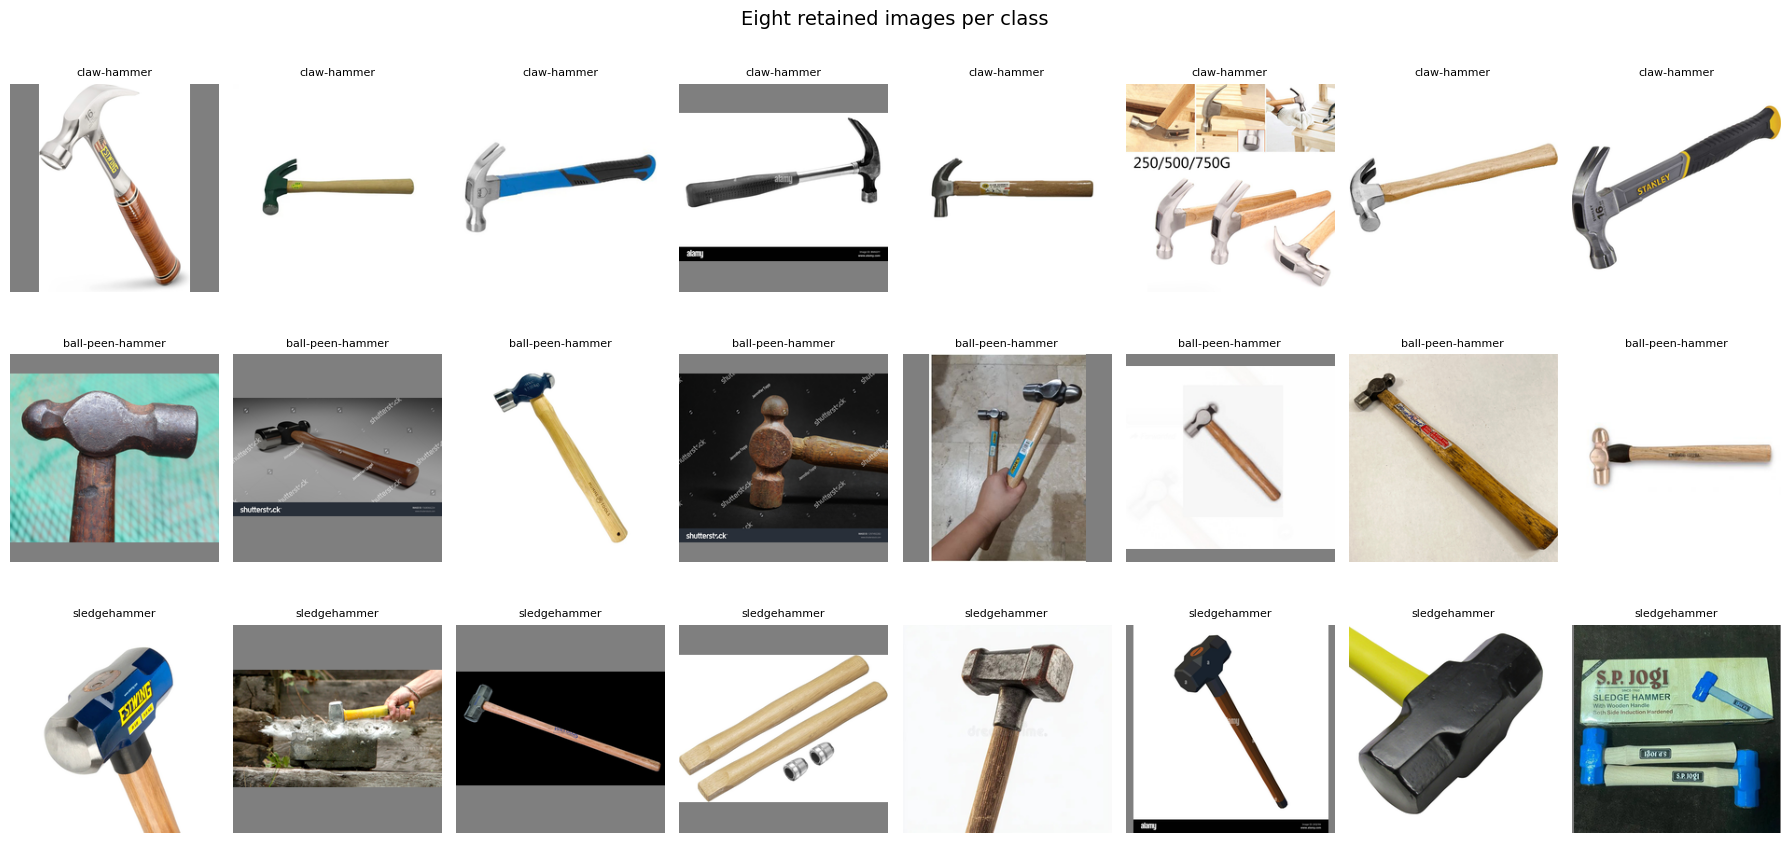

In [20]:
fig, axes = plt.subplots(
    len(LABELS),
    8,
    figsize=(18, 3 * len(LABELS)),
    squeeze=False
)

for row_number, label in enumerate(LABELS):
    class_records = kept.loc[kept['label'].eq(label)]

    assert len(class_records) >= 8, (
        f'{label} has fewer than eight retained images.'
    )

    examples = class_records.sample(
        n=8, random_state=SEED
    )

    for axis, row in zip(
        axes[row_number],
        examples.itertuples(index=False)
    ):
        with Image.open(
            RAW / row.label / row.filename
        ) as image:
            preview = resize_rgb(
                image,
                tuple(config['target_size']),
                tuple(config['padding_rgb'])
            )
            axis.imshow(preview)

        axis.set_title(label, fontsize=8)
        axis.axis('off')

plt.suptitle('Eight retained images per class', fontsize=14)
plt.tight_layout()
plt.show()

#### Outcome and visual interpretation — retained sample

The saved grid contains **24 images: eight per class**.

| Class | Visible findings in the saved grid | Interpretation and follow-up |
|---|---|---|
| Claw hammer | Curved and straighter claws; wood, metal, and composite-looking handles; mostly white product backgrounds; branding and a stock-image watermark. A multi-image product collage is still visible in the sixth column. | Claw shape is a plausible class cue. Review the remaining collage before finalizing the data; white backgrounds, seller graphics, and logos could become shortcuts. |
| Ball-peen hammer | Rounded peens, worn and newer metal heads, close-ups and whole-tool views, colored or workshop backgrounds, several stock-image watermarks, and a photograph containing more than one tool. | Viewpoint and wear add variation. Review ambiguous multi-tool scenes and whether the intended head is visible; watermarks and source backgrounds may be distracting cues. |
| Sledgehammer | Broad heads, different handle lengths, product and in-use views, head close-ups, branding, and stock-image borders. The fourth column appears to show replacement handles/components rather than an assembled hammer. | Review the parts-only listing for removal; tight crops can hide class-defining proportions. Packaging and background differences should be tested as possible shortcuts. |

Visible grey bands are consistent with the configured padding; original white margins, logos, and stock-image banners are separate source-image features. This grid shows that the 14 removals resolved the documented groups but did **not** establish complete semantic cleaning. Additional decisions must be recorded, counts recomputed, and arrays regenerated if more images are removed. These observations also motivate the later shortcut analysis in Notebook 4; no shortcut effect has been experimentally established here.


### 2.2 Measure Dimensions, Aspect Ratios, and Class Support

**Task:** Quantify source-image variation and natural class support after the documented removals.

**Decision:** Measure the retained images before balancing, augmentation, or any model-specific scaling. Keep the observed class counts unchanged.

**Steps taken:** Compute minimum, maximum, and median width, height, and width/height ratio per class; plot distributions and retained counts; calculate the largest/smallest class ratio.

**Explanation:** Native dimensions determine how much resizing and padding each image needs. These are original dimensions recorded by inventory, not the already padded 224-by-224 preview dimensions. Class support is reported after the 14 removals, so it differs slightly from Notebook 1's equal 400-per-class acquisition counts. Any later balancing decision belongs in Notebook 3 and must use only training data.


width                 height                 aspect_ratio  \
                    min     max  median    min     max  median          min   
label                                                                         
ball-peen-hammer  250.0  4032.0  1000.0  250.0  3447.0  1000.0     0.602158   
claw-hammer       265.0  4386.0  1000.0  236.0  4096.0   956.0     0.523771   
sledgehammer      250.0  4608.0  1000.0  250.0  3719.0   900.0     0.513714   

                              
                  max median  
label                         
ball-peen-hammer  2.0    1.0  
claw-hammer       2.0    1.0  
sledgehammer      2.0    1.0

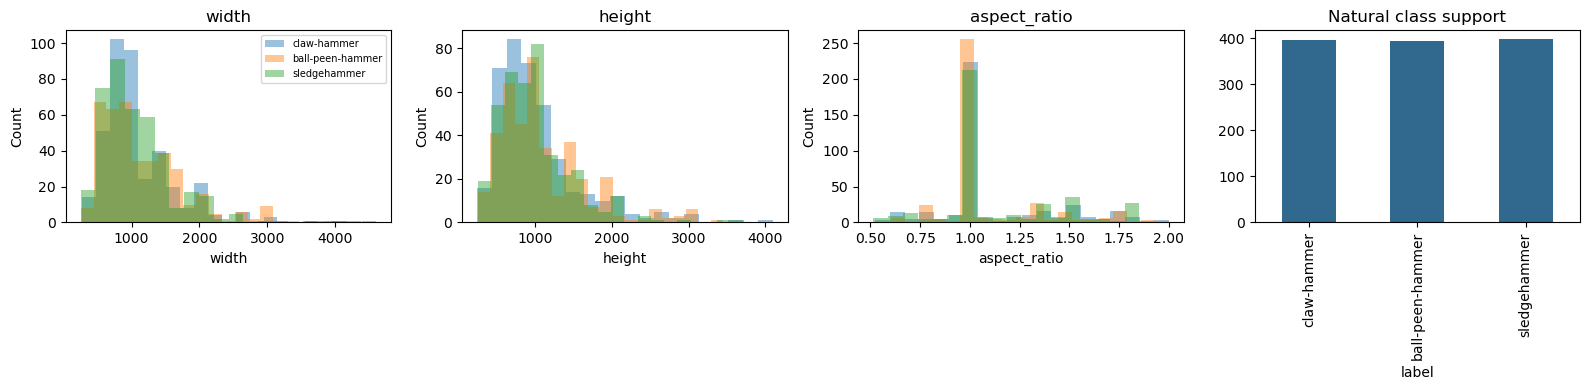

**Observed imbalance:** largest/smallest = 1.01. No balancing has been applied.

**Interpretation:** retained counts range from 394 to 397; imbalance is mild under descriptive cutoffs 1.5 and 2.0. These are reporting conventions, not statistical tests. Leave all counts unchanged until training-only decisions in Notebook 3.

**ball-peen-hammer:** width 250–4032 px (median 1000); height 250–3447 px (median 1000); aspect ratio 0.60–2.00 (median 1.00). Compare these ranges with the histograms before describing size consistency.

**claw-hammer:** width 265–4386 px (median 1000); height 236–4096 px (median 956); aspect ratio 0.52–2.00 (median 1.00). Compare these ranges with the histograms before describing size consistency.

**sledgehammer:** width 250–4608 px (median 1000); height 250–3719 px (median 900); aspect ratio 0.51–2.00 (median 1.00). Compare these ranges with the histograms before describing size consistency.

In [21]:
dimension_summary = kept.groupby('label')[['width','height','aspect_ratio']].agg(['min','max','median'])
display(dimension_summary)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for column, axis in zip(['width','height','aspect_ratio'], axes[:3]):
    for label in support.index:
        axis.hist(kept.loc[kept.label.eq(label), column], bins=20, alpha=.45, label=label)
    axis.set_title(column); axis.set_xlabel(column); axis.set_ylabel('Count')
axes[0].legend(fontsize=7)
support.plot.bar(ax=axes[3], color='#31688e'); axes[3].set_title('Natural class support')
plt.tight_layout(); plt.show()
ratio = float(support.max()/support.min())
display(Markdown(f'**Observed imbalance:** largest/smallest = {ratio:.2f}. No balancing has been applied.'))
dimension_summary.to_csv(ROOT / 'data/P2_dimension_summary.csv')
severity = 'none' if ratio == 1 else ('mild' if ratio < 1.5 else ('moderate' if ratio < 2 else 'substantial'))
display(Markdown(f'**Interpretation:** retained counts range from {support.min()} to {support.max()}; '
                 f'imbalance is {severity} under descriptive cutoffs 1.5 and 2.0. These are reporting conventions, '
                 'not statistical tests. Leave all counts unchanged until training-only decisions in Notebook 3.'))
for label, part in kept.groupby('label'):
    display(Markdown(f"**{label}:** width {int(part.width.min())}–{int(part.width.max())} px "
                     f"(median {part.width.median():.0f}); height {int(part.height.min())}–{int(part.height.max())} px "
                     f"(median {part.height.median():.0f}); aspect ratio {part.aspect_ratio.min():.2f}–"
                     f"{part.aspect_ratio.max():.2f} (median {part.aspect_ratio.median():.2f}). "
                     'Compare these ranges with the histograms before describing size consistency.'))


#### Outcome — Dimensions and Class Support

The recorded native-image statistics are:

| Class | Width min / max / median (px) | Height min / max / median (px) | Aspect ratio min / max / median |
|---|---|---|---|
| Claw hammer | 265 / 4,386 / 1,000 | 236 / 4,096 / 956 | 0.524 / 2.000 / 1.000 |
| Ball-peen hammer | 250 / 4,032 / 1,000 | 250 / 3,447 / 1,000 | 0.602 / 2.000 / 1.000 |
| Sledgehammer | 250 / 4,608 / 1,000 | 250 / 3,719 / 900 | 0.514 / 2.000 / 1.000 |

Widths vary from **250 to 4,608 pixels** overall and heights from **236 to 4,096 pixels**. All classes have a median aspect ratio of **1.00**, but the full range includes portrait and wide landscape images. The saved histograms have a strong concentration near square images and long tails in source resolution.

Class support is **395 claw-hammer, 394 ball-peen-hammer, and 397 sledgehammer images**. The largest/smallest ratio is **397 / 394 = 1.0076**, displayed as **1.01**. The largest class has just **three more images** than the smallest. The source output labels this “mild” under its descriptive cutoffs; in practical count terms the classes are nearly balanced.

**Interpretation:** Source resolutions are substantially inconsistent despite the common median width and aspect ratio. A fixed input size is therefore needed, and non-square images will receive padding. There is no substantial support imbalance to correct at this stage. I applied **no balancing or augmentation**; Notebook 3 can revisit training-only needs without altering the held-out test distribution.


### 3.1 Normalize to RGB and Preserve Aspect Ratio With Padding

**Task:** Create consistent image tensors and compute a mean image for each class.

**Decision:** Use **224 × 224 × 3 RGB images**, stored as **uint8 with raw 0–255 intensities**, and preserve the full image through aspect-ratio-preserving resize and centered neutral-grey padding.

**Steps taken:**

1. Confirm each retained source file still matches the checksum recorded during inventory.
2. Call `resize_rgb` imported from `pipeline_utils` using the shared target size and padding configuration. The intended shared-helper preprocessing handles orientation and transparency as well as resizing and padding; the helper source is not included in this upload for independent verification of those internals.
3. Check each output shape and dtype, stack the arrays in retained-record order, and hash the actual resized pixels.
4. Average the resized arrays separately within each class to create the three mean-image visualizations.

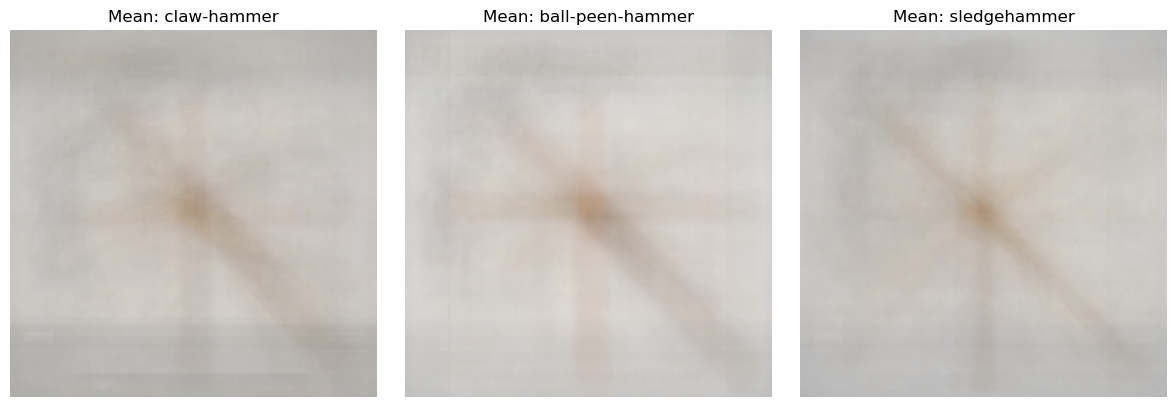

Raw RGB array: (1186, 224, 224, 3) uint8
Observed pixel range: 0 255


**Preprocessing output:** 1186 images, each 224 × 224 × 3, stored as uint8. The observed pixel range is 0–255. No scaling, balancing, or augmentation has been applied.

In [22]:
TARGET_SIZE = tuple(config['target_size'])
PADDING_RGB = tuple(config['padding_rgb'])

# Remember the manifest associated with this preprocessing run.
PREPROCESSING_MANIFEST_SHA256 = digest(MANIFEST_PATH)

arrays = []

for row in kept.itertuples(index=False):
    path = RAW / row.label / row.filename

    assert path.is_file(), (
        f'A retained file is now missing: {path}'
    )
    assert digest(path) == row.file_sha256, (
        f'A retained file changed after inventory: {path}. '
        'Rerun cleaning and inventory before preprocessing.'
    )

    with Image.open(path) as image:
        image.load()
        array = np.asarray(
            resize_rgb(image, TARGET_SIZE, PADDING_RGB)
        )

    assert array.dtype == np.uint8, (
        f'Expected raw uint8 pixels: {path}'
    )
    assert array.shape == (224, 224, 3), (
        f'Unexpected resized shape {array.shape}: {path}'
    )

    arrays.append(array)

X = np.stack(arrays)

assert X.shape == (len(kept), 224, 224, 3)
assert X.dtype == np.uint8

# Record exact identities of the actual model-input pixels.
kept['prepared_pixel_sha256'] = [
    hashlib.sha256(
        np.ascontiguousarray(array).tobytes()
    ).hexdigest()
    for array in X
]

fig, axes = plt.subplots(
    1,
    len(LABELS),
    figsize=(4 * len(LABELS), 4),
    squeeze=False
)

for axis, label in zip(axes[0], LABELS):
    mask = kept['label'].eq(label).to_numpy()
    mean_image = X[mask].mean(axis=0)

    axis.imshow(
        np.clip(mean_image, 0, 255).astype(np.uint8)
    )
    axis.set_title('Mean: ' + label)
    axis.axis('off')

plt.tight_layout()
plt.show()

print('Raw RGB array:', X.shape, X.dtype)
print('Observed pixel range:', int(X.min()), int(X.max()))

display(Markdown(
    f'**Preprocessing output:** {len(X)} images, each '
    f'{X.shape[1]} × {X.shape[2]} × 3, stored as uint8. '
    f'The observed pixel range is {int(X.min())}–{int(X.max())}. '
    'No scaling, balancing, or augmentation has been applied.'
))


#### Outcome — RGB arrays and class means

The saved preprocessing output is **`(1186, 224, 224, 3)`**, with dtype **`uint8`** and an observed pixel range of **0–255**. No scaling, balancing, or augmentation was applied. Three mean images were displayed, each averaged over all retained images of its class.

| Class mean | Visible appearance | Interpretation |
|---|---|---|
| Claw hammer | Pale overall background, a diffuse warm-toned central/diagonal region, and darker horizontal bands near the bottom. | Consistent product framing, source banners, and padding could contribute to the average. A distinctive claw is not clearly resolved in the mean. |
| Ball-peen hammer | Light background, diffuse warm-toned structure near the center, and faint horizontal or rectangular tonal bands. | Shared handle colors and product presentation may contribute, but the rounded peen is not sharply identifiable in the mean. |
| Sledgehammer | Pale background with a diffuse diagonal warm-toned region and darker shading toward the lower edge/corners. | Repeated handle orientation and framing may contribute; neither head geometry nor source-versus-padding contributions can be isolated from the mean alone. |

**Interpretation:** The means are blurred and visually similar; they do not demonstrate class separability or the absence of shortcuts. Neutral-grey padding can contribute border shading, while original stock-image banners, white margins, and branding are visible in the sample grid. The exact contribution of each requires follow-up rather than attribution from averages alone. Notebook 4 should test candidate background, border, and watermark cues using the assigned explanation and occlusion methods after modeling.


### 4.1 Make the Stratified Split and Export Independent Handoffs

**Task:** Save a reproducible working train/test handoff for Notebooks 3 and 4 and the app.

**Decision:** Split original retained-image indices **80/20**, stratified by class, using **`random_state=42`**. Do not balance or augment before the split. Save raw uint8 images, integer labels, one alphabetical label mapping, and row-aligned identity records.

**Steps taken:**

1. Confirm the manifest and retained source files have not changed since preprocessing.
2. Map the three class labels to stable alphabetical indices.
3. Split indices with `train_test_split(test_size=0.20, stratify=y, random_state=42)`.
4. Check index separation and absence of exact decoded-pixel and resized-pixel hash overlap across train and test.
5. Export separate `.npy` arrays and row-aligned CSV identity files outside the repository, plus `label_to_index.json` and `preprocessing.json`.
6. Record manifest/configuration/export checksums and reload the saved arrays to check their shape, dtype, and values against the in-memory exports.

In [23]:
assert support.ge(200).all()
assert len(X) == len(kept)
assert X.dtype == np.uint8
assert X.shape[1:] == (224, 224, 3)

assert digest(MANIFEST_PATH) == PREPROCESSING_MANIFEST_SHA256, (
    'The manifest changed after preprocessing. '
    'Rerun Notebook 2 before exporting.'
)

# Confirm retained source files still match the reviewed inventory.
for row in kept.itertuples(index=False):
    path = RAW / row.label / row.filename
    assert path.is_file() and digest(path) == row.file_sha256, (
        f'A retained source file changed or disappeared: {path}'
    )

# Stable alphabetical mapping, reused by N3, N4, and the app.
mapping = {
    label: index
    for index, label in enumerate(sorted(LABELS))
}
y = kept['label'].map(mapping).to_numpy(dtype=np.int64)

assert not pd.isna(y).any()
assert set(np.unique(y)) == set(mapping.values())

train_index, test_index = train_test_split(
    np.arange(len(kept)),
    test_size=0.20,
    stratify=y,
    random_state=42
)

assert len(train_index) + len(test_index) == len(kept)
assert set(train_index).isdisjoint(test_index)

# Check original decoded images and actual resized model inputs.
for hash_column in [
    'pixel_sha256',
    'prepared_pixel_sha256'
]:
    train_hashes = set(
        kept.iloc[train_index][hash_column]
    )
    test_hashes = set(
        kept.iloc[test_index][hash_column]
    )
    assert train_hashes.isdisjoint(test_hashes), (
        f'Exact train/test overlap detected using {hash_column}. '
        'Review duplicate images and regenerate the split.'
    )

# Record both the split and row position in its corresponding array.
identity = kept[[
    'filename',
    'label',
    'file_sha256',
    'pixel_sha256',
    'prepared_pixel_sha256'
]].copy()

identity['label_index'] = y
identity['split'] = ''
identity['array_row'] = -1

identity.loc[train_index, 'split'] = 'train'
identity.loc[test_index, 'split'] = 'test'
identity.loc[train_index, 'array_row'] = np.arange(len(train_index))
identity.loc[test_index, 'array_row'] = np.arange(len(test_index))

split_counts = pd.crosstab(
    identity['label'], identity['split']
).reindex(
    index=sorted(LABELS),
    columns=['train', 'test'],
    fill_value=0
)

assert split_counts.gt(0).all().all()
display(split_counts)

# Save images as raw uint8 arrays; scaling belongs in Notebook 3.
PREPARED.mkdir(parents=True, exist_ok=True)

exports = {
    'X_train': X[train_index],
    'X_test': X[test_index],
    'y_train': y[train_index],
    'y_test': y[test_index]
}

for name, array in exports.items():
    np.save(
        PREPARED / f'{name}.npy',
        array,
        allow_pickle=False
    )

identity.to_csv(
    PREPARED / 'split_identity.csv', index=False
)

for split_name, indices in [
    ('train', train_index),
    ('test', test_index)
]:
    split_identity = identity.iloc[indices].copy()

    assert np.array_equal(
        split_identity['array_row'].to_numpy(),
        np.arange(len(indices))
    )
    assert np.array_equal(
        split_identity['label_index'].to_numpy(),
        exports[f'y_{split_name}']
    )

    split_identity.to_csv(
        PREPARED / f'{split_name}_identity.csv',
        index=False
    )

save_json(PREPARED / 'label_to_index.json', mapping)

files = [
    'X_train.npy',
    'X_test.npy',
    'y_train.npy',
    'y_test.npy',
    'label_to_index.json',
    'split_identity.csv',
    'train_identity.csv',
    'test_identity.csv'
]

metadata = {
    'target_size': list(TARGET_SIZE),
    'resize_strategy': 'pad',
    'padding_rgb': list(PADDING_RGB),
    'color_mode': 'RGB',
    'dtype': 'uint8',
    'range': [0, 255],
    'observed_pixel_range': [int(X.min()), int(X.max())],
    'random_state': 42,
    'test_size': 0.20,
    'stratified': True,
    'balanced_before_split': False,
    'augmented_before_split': False,
    'train_count': int(len(train_index)),
    'test_count': int(len(test_index)),
    'manifest_sha256': digest(MANIFEST_PATH),
    'config_sha256': digest(ROOT / 'config/project.json'),
    'files_sha256': {
        name: digest(PREPARED / name)
        for name in files
    }
}

save_json(PREPARED / 'preprocessing.json', metadata)

# Verify the saved arrays without loading additional copies into memory.
for name, expected in exports.items():
    saved = np.load(
        PREPARED / f'{name}.npy',
        mmap_mode='r',
        allow_pickle=False
    )
    assert saved.shape == expected.shape
    assert saved.dtype == expected.dtype
    assert np.array_equal(saved, expected)
    del saved

print('Prepared exports:', PREPARED)
print('Label mapping:', mapping)

display(Markdown(
    f'**Split outcome:** {len(train_index)} training images and '
    f'{len(test_index)} test images '
    f'({len(test_index) / len(kept):.1%} test). '
    'The split is stratified with random_state=42. '
    'No exact decoded or resized image occurs in both splits. '
    'Near-duplicate control still depends on manual review.'
))

split,train,test
label,,
ball-peen-hammer,315,79
claw-hammer,316,79
sledgehammer,317,80


Prepared exports: C:\Users\lawra\Fall 2026-2027 Semester Document\MSDS 565-01\Project 2 Image Classification\Images\prepared
Label mapping: {'ball-peen-hammer': 0, 'claw-hammer': 1, 'sledgehammer': 2}


**Split outcome:** 948 training images and 238 test images (20.1% test). The split is stratified with random_state=42. No exact decoded or resized image occurs in both splits. Near-duplicate control still depends on manual review.

#### Outcome — Recorded Split and Exported Files

| Class | Label index | Train | Test | Total |
|---|---:|---:|---:|---:|
| Ball-peen hammer | 0 | 315 | 79 | 394 |
| Claw hammer | 1 | 316 | 79 | 395 |
| Sledgehammer | 2 | 317 | 80 | 397 |
| **Total** | — | **948** | **238** | **1,186** |

The realized split is **79.93% training and 20.07% test** (displayed as **20.1% test**). The saved source cell completed without an error, including the exact-overlap assertions and the array reload checks. No exact decoded-image or resized-input hash was shared between its train and test sets. Near-duplicate leakage is not ruled out by that result.

The recorded destination is the external **`Images/prepared`** folder. The export code writes:

| Files | Purpose |
|---|---|
| `X_train.npy`, `X_test.npy` | Raw RGB uint8 arrays, expected shapes `(948, 224, 224, 3)` and `(238, 224, 224, 3)` from the recorded split |
| `y_train.npy`, `y_test.npy` | Integer class labels in matching array order, lengths 948 and 238 |
| `label_to_index.json` | Identical mapping for later notebooks and the app: ball-peen-hammer → 0, claw-hammer → 1, sledgehammer → 2 |
| `split_identity.csv`, `train_identity.csv`, `test_identity.csv` | Filename, class, hash, label index, split, and array-row identities |
| `preprocessing.json` | Target size, padding, dtype/range, split settings, counts, and checksums |

**Interpretation:** Notebook 3 must load these persisted arrays and mapping rather than create a fresh split. It may balance or augment training data only. The saved outputs establish a successful working export; the Windows files were not supplied for an independent recheck during this editorial revision. Finish the remaining semantic/near-duplicate review and regenerate the handoff if additional files are removed.

**Recorded completion:** Inventory, the nine-group visual review and 14 removals, retention accounting, EDA, preprocessing, and export are documented with saved evidence. 